# Regularized Regression Diagnostics

This notebook evaluates residual behavior, normality, predictor correlation, and potential error dependence for the five primary regularized regression specifications. It reproduces the same feature sets, scaling pipelines, hyperparameter grids, development seasons, and seven-fold leave-one-season-out validation used in `primary.ipynb`.

All residual diagnostics use out-of-fold development predictions: each observation is predicted by a model that did not train on that observation's season. Because hyperparameters are selected using these same folds, the diagnostics are exploratory rather than fully independent. The reserved test sample is not used to revise model specifications, and no supplementary OLS models or formal hypothesis tests are introduced.


## 1. Imports and shared configuration


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

from sklearn.base import clone
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 4031
DEVELOPMENT_SEASONS = list(range(2016, 2023))
TEST_SEASONS = list(range(2023, 2026))
SEASON_LABELS = {
    season: f"{season}/{str(season + 1)[-2:]}"
    for season in range(2016, 2026)
}

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


## 2. Load data and define the existing experiments


In [2]:
def locate_dataset(filename="epl_merged_data.xlsx"):
    for root in [Path.cwd(), *Path.cwd().parents]:
        candidate = root / "outputs" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate outputs/{filename} from {Path.cwd().resolve()}"
    )


dataset_path = locate_dataset()
modeling_data = pd.read_excel(dataset_path)

required_columns = {
    "Season", "Team", "Promoted", "Curr_Points", "EOS_Total_Points"
}
missing_required = sorted(required_columns.difference(modeling_data.columns))
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")
if modeling_data.duplicated(["Season", "Team"]).any():
    raise ValueError("The dataset contains duplicate Season-Team observations.")

modeling_data["Remaining_Points"] = (
    modeling_data["EOS_Total_Points"] - modeling_data["Curr_Points"]
)

CURRENT_PERFORMANCE_FEATURES = [
    "Curr_Avg_Win_Percentage",
    "Curr_Avg_Draw_Percentage",
    "Curr_Avg_Goals",
    "Curr_Avg_SOT",
    "Curr_Avg_Opp_Goals",
    "Curr_Avg_Opp_SOT",
    "Curr_Avg_xG",
    "Curr_Avg_xGA",
    "Curr_Avg_Deep",
    "Curr_Avg_Deep_Allowed",
    "Curr_Points",
]
PREVIOUS_SEASON_FEATURES = [
    "Prev_Total_Points",
    "Prev_Avg_Goals",
    "Prev_Avg_SOT",
    "Prev_Avg_Opp_Goals",
    "Prev_Avg_Opp_SOT",
    "Prev_Avg_xG",
    "Prev_Avg_xGA",
    "Prev_Points",
]
TRANSFER_FEATURES = [
    "Fee_Spending",
    "Fee_Earnings",
    "Permanent_In_Count",
    "Permanent_Out_Count",
]

EXPERIMENTS = {
    "Experiment A: Current performance": CURRENT_PERFORMANCE_FEATURES,
    "Experiment B: Current + previous season": (
        CURRENT_PERFORMANCE_FEATURES
        + PREVIOUS_SEASON_FEATURES
        + ["Promoted"]
    ),
    "Experiment C: Current + previous + transfers": (
        CURRENT_PERFORMANCE_FEATURES
        + PREVIOUS_SEASON_FEATURES
        + ["Promoted"]
        + TRANSFER_FEATURES
    ),
}
TARGET = "Remaining_Points"

for experiment_name, features in EXPERIMENTS.items():
    missing = sorted(set(features).difference(modeling_data.columns))
    if missing:
        raise KeyError(f"{experiment_name} is missing predictors: {missing}")
    if modeling_data[features].isna().any().any():
        raise ValueError(f"{experiment_name} contains missing predictor values.")

print(f"Loaded: {dataset_path.resolve()}")
print(f"Observations: {len(modeling_data):,}")


Loaded: C:\Users\micha\epl_results_prediction\outputs\epl_merged_data.xlsx
Observations: 200


## 3. Reproduce development, validation, and test samples


In [3]:
development = (
    modeling_data.loc[modeling_data["Season"].isin(DEVELOPMENT_SEASONS)]
    .sort_values(["Season", "Team"])
    .reset_index(drop=True)
)
test_data = (
    modeling_data.loc[modeling_data["Season"].isin(TEST_SEASONS)]
    .sort_values(["Season", "Team"])
    .reset_index(drop=True)
)

cv_splits = []
for validation_season in DEVELOPMENT_SEASONS:
    train_indices = np.flatnonzero(
        development["Season"].ne(validation_season)
    )
    validation_indices = np.flatnonzero(
        development["Season"].eq(validation_season)
    )
    if not len(validation_indices):
        raise ValueError(f"No validation observations for {validation_season}.")
    cv_splits.append((train_indices, validation_indices))

print(f"Development observations: {len(development):,}")
print(f"Validation folds: {len(cv_splits)}")
print(f"Reserved test observations: {len(test_data):,}")


Development observations: 140
Validation folds: 7
Reserved test observations: 60


## 4. Reproduce the five model specifications


In [4]:
MODEL_SPECS = {
    "Elastic Net": {
        "pipeline": Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    ElasticNet(
                        max_iter=100_000,
                        tol=1e-4,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "grid": {
            "model__alpha": np.logspace(-3, 2, 25),
            "model__l1_ratio": [
                0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 1.00
            ],
        },
    },
    "Ridge": {
        "pipeline": Pipeline(
            [("scaler", StandardScaler()), ("model", Ridge())]
        ),
        "grid": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "Lasso": {
        "pipeline": Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    Lasso(
                        max_iter=100_000,
                        tol=1e-4,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "grid": {"model__alpha": np.logspace(-3, 2, 50)},
    },
}
SCORING = {
    "mse": "neg_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

MODEL_EXPERIMENT_RUNS = [
    ("Experiment A: Current performance", "Elastic Net"),
    ("Experiment B: Current + previous season", "Elastic Net"),
    ("Experiment C: Current + previous + transfers", "Elastic Net"),
    ("Experiment C: Current + previous + transfers", "Ridge"),
    ("Experiment C: Current + previous + transfers", "Lasso"),
]


## 5. Generate out-of-fold development predictions

MSE remains the hyperparameter-selection criterion. After selecting each specification with the existing folds, the selected pipeline is refitted separately within every fold to generate out-of-fold predictions. The audit table verifies that all 140 development observations receive predictions.


In [5]:
def fit_oof_diagnostics(experiment_name, model_name, features):
    model_spec = MODEL_SPECS[model_name]
    X_development = development[features]
    y_development = development[TARGET]

    search = GridSearchCV(
        estimator=clone(model_spec["pipeline"]),
        param_grid=model_spec["grid"],
        scoring=SCORING,
        refit="mse",
        cv=cv_splits,
        n_jobs=-1,
        error_score="raise",
    )
    search.fit(X_development, y_development)

    oof_predictions = np.full(len(development), np.nan)
    for train_indices, validation_indices in cv_splits:
        fold_model = clone(search.best_estimator_)
        fold_model.fit(
            X_development.iloc[train_indices],
            y_development.iloc[train_indices],
        )
        oof_predictions[validation_indices] = fold_model.predict(
            X_development.iloc[validation_indices]
        )

    if np.isnan(oof_predictions).any():
        raise ValueError("At least one development observation lacks an OOF prediction.")

    oof_results = development[
        [
            "Season",
            "Team",
            "Promoted",
            "Curr_Points",
            "Remaining_Points",
            "EOS_Total_Points",
        ]
    ].copy()
    oof_results["Predicted_Remaining_Points"] = oof_predictions
    oof_results["Residual"] = (
        oof_results["Remaining_Points"]
        - oof_results["Predicted_Remaining_Points"]
    )
    oof_results["Predicted_Final_Points"] = (
        oof_results["Curr_Points"]
        + oof_results["Predicted_Remaining_Points"]
    )

    return {
        "Label": f"{model_name} | {experiment_name}",
        "Short_Label": f"{model_name} - {experiment_name.split(chr(58))[0]}",
        "Experiment": experiment_name,
        "Model": model_name,
        "Features": features,
        "Best_Parameters": search.best_params_,
        "OOF_Results": oof_results,
        "OOF_MSE": mean_squared_error(
            oof_results["Remaining_Points"], oof_predictions
        ),
        "OOF_MAE": mean_absolute_error(
            oof_results["Remaining_Points"], oof_predictions
        ),
        "OOF_R2": r2_score(
            oof_results["Remaining_Points"], oof_predictions
        ),
    }


diagnostic_results = []
for experiment_name, model_name in MODEL_EXPERIMENT_RUNS:
    print(f"Fitting {model_name} - {experiment_name} ...")
    diagnostic_results.append(
        fit_oof_diagnostics(
            experiment_name,
            model_name,
            EXPERIMENTS[experiment_name],
        )
    )

audit_summary = pd.DataFrame(
    [
        {
            "Experiment": result["Experiment"],
            "Model": result["Model"],
            "OOF_Observations": len(result["OOF_Results"]),
            "OOF_MSE": result["OOF_MSE"],
            "OOF_MAE": result["OOF_MAE"],
            "OOF_RMSE": np.sqrt(result["OOF_MSE"]),
            "OOF_R2": result["OOF_R2"],
            "Best_Parameters": result["Best_Parameters"],
        }
        for result in diagnostic_results
    ]
)
display(audit_summary)


Fitting Elastic Net - Experiment A: Current performance ...


Fitting Elastic Net - Experiment B: Current + previous season ...


Fitting Elastic Net - Experiment C: Current + previous + transfers ...


Fitting Ridge - Experiment C: Current + previous + transfers ...


Fitting Lasso - Experiment C: Current + previous + transfers ...


,Experiment,Model,OOF_Observations,OOF_MSE,OOF_MAE,OOF_RMSE,OOF_R2,Best_Parameters
0,Experiment A: Current performance,Elastic Net,140,84.682,7.589,9.202,0.562,"{'model__alpha': 0.825404185268019, 'model__l1..."
1,Experiment B: Current + previous season,Elastic Net,140,77.427,7.186,8.799,0.600,"{'model__alpha': 0.825404185268019, 'model__l1..."
2,Experiment C: Current + previous + transfers,Elastic Net,140,73.540,6.929,8.576,0.620,"{'model__alpha': 0.825404185268019, 'model__l1..."
3,Experiment C: Current + previous + transfers,Ridge,140,73.418,6.930,8.568,0.620,{'model__alpha': 104.81131341546852}
4,Experiment C: Current + previous + transfers,Lasso,140,78.223,7.056,8.844,0.596,{'model__alpha': 0.4498432668969444}


## 6. Shared plotting helpers


In [6]:
def diagnostic_axes(title, sharex=True, sharey=True):
    fig, axes = plt.subplots(
        3,
        2,
        figsize=(14, 15),
        sharex=sharex,
        sharey=sharey,
    )
    axes = axes.flatten()
    axes[-1].set_visible(False)
    fig.suptitle(title, fontsize=15, y=0.995)
    return fig, axes


def padded_limits(values, padding=0.05):
    values = np.asarray(values, dtype=float)
    minimum = np.nanmin(values)
    maximum = np.nanmax(values)
    span = maximum - minimum
    if np.isclose(span, 0):
        span = 1.0
    return minimum - padding * span, maximum + padding * span


## 7. Residuals versus fitted values

Residuals should be examined for curvature, funnels, clusters, or systematic displacement from zero. The LOWESS curve is an exploratory guide to possible structure; it is not a formal test and should not by itself be used to declare an assumption satisfied or violated.


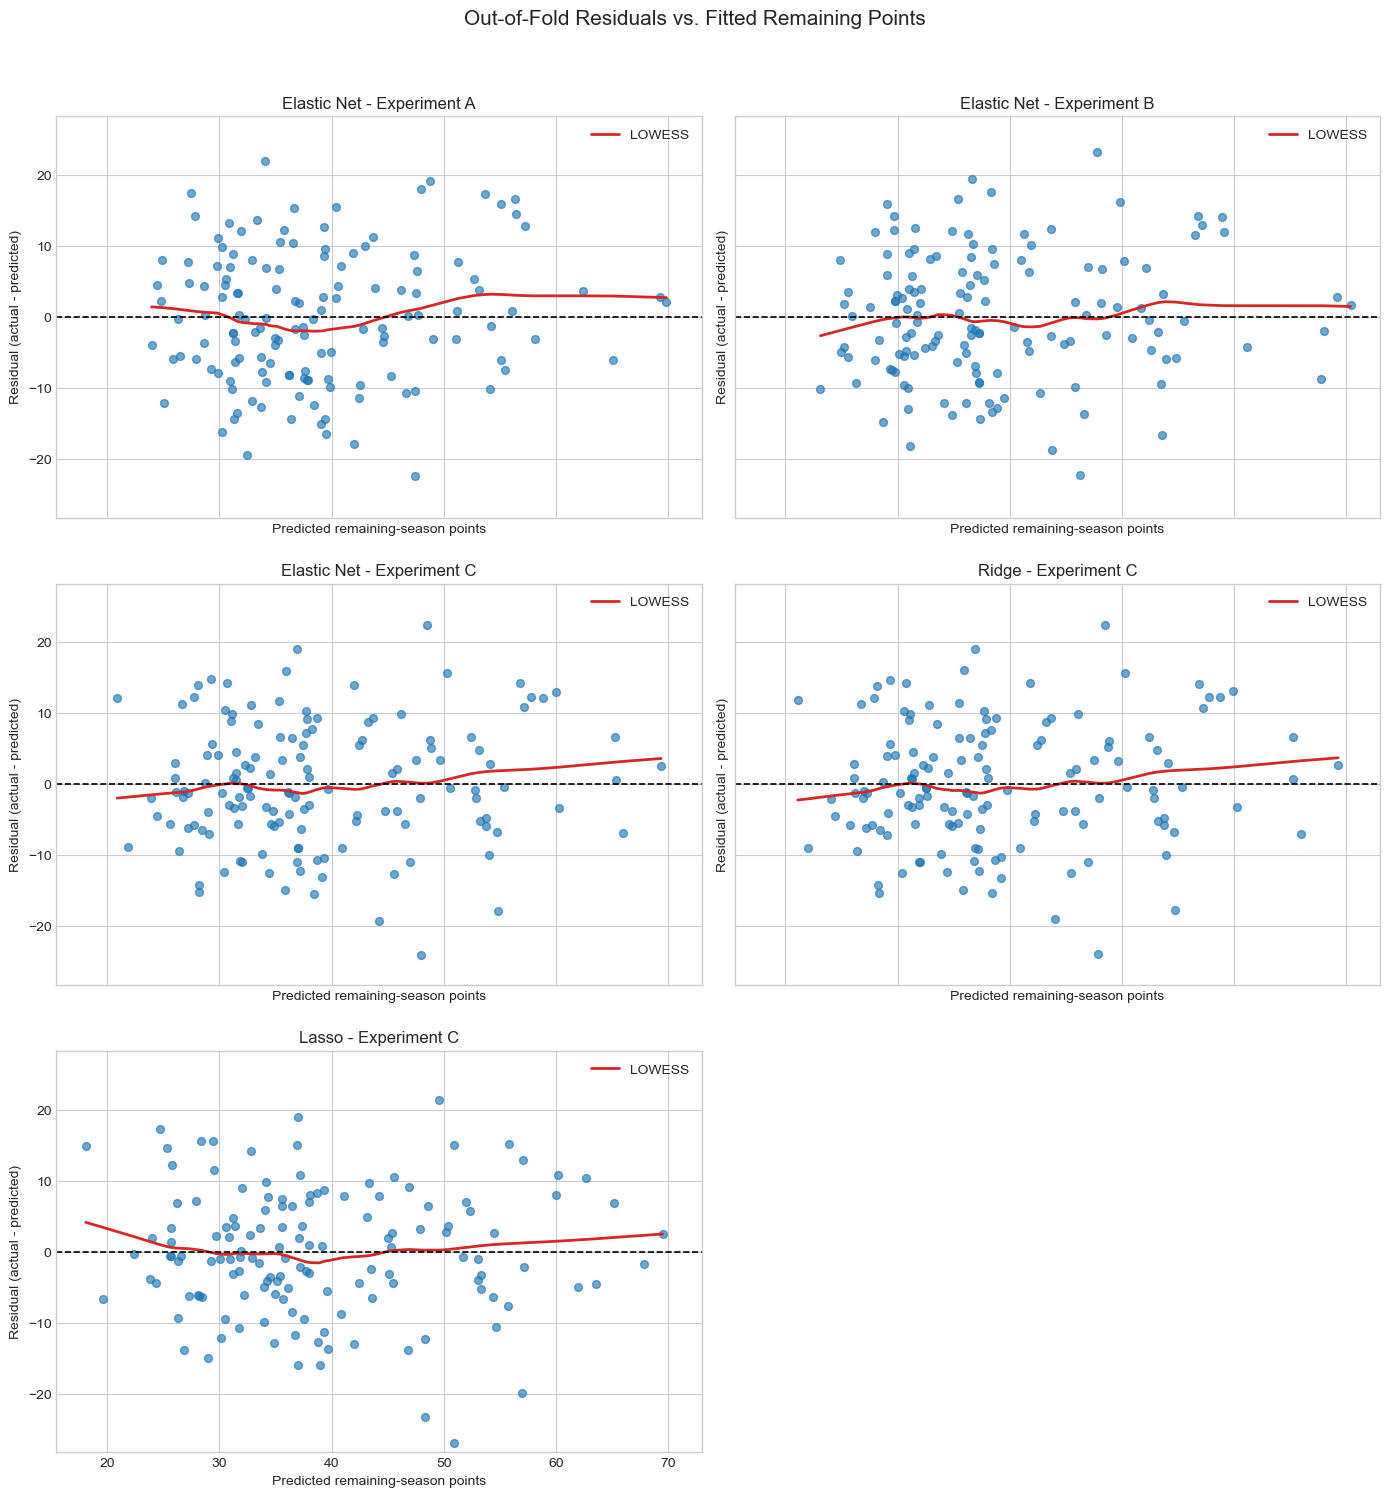

In [7]:
all_fitted = np.concatenate(
    [result["OOF_Results"]["Predicted_Remaining_Points"] for result in diagnostic_results]
)
all_residuals = np.concatenate(
    [result["OOF_Results"]["Residual"] for result in diagnostic_results]
)
x_limits = padded_limits(all_fitted)
residual_limit = 1.05 * np.max(np.abs(all_residuals))

fig, axes = diagnostic_axes(
    "Out-of-Fold Residuals vs. Fitted Remaining Points"
)
for axis, result in zip(axes, diagnostic_results):
    data = result["OOF_Results"]
    fitted = data["Predicted_Remaining_Points"].to_numpy()
    residuals = data["Residual"].to_numpy()
    smoothed = lowess(residuals, fitted, frac=0.45, return_sorted=True)

    axis.scatter(fitted, residuals, alpha=0.65, s=32)
    axis.plot(
        smoothed[:, 0],
        smoothed[:, 1],
        color="tab:red",
        linewidth=2,
        label="LOWESS",
    )
    axis.axhline(0, color="black", linestyle="--", linewidth=1.2)
    axis.set_title(result["Short_Label"])
    axis.set_xlim(x_limits)
    axis.set_ylim(-residual_limit, residual_limit)
    axis.set_xlabel("Predicted remaining-season points")
    axis.set_ylabel("Residual (actual - predicted)")
    axis.legend(loc="best")

fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.0)
plt.show()


## 8. Normal Q-Q plots

Points near the reference line indicate residual quantiles broadly consistent with a normal distribution. Departures in the center or tails help identify skewness and unusually heavy or light tails. Forecast performance does not require perfectly normal residuals, and these plots do not provide a formal normality test.


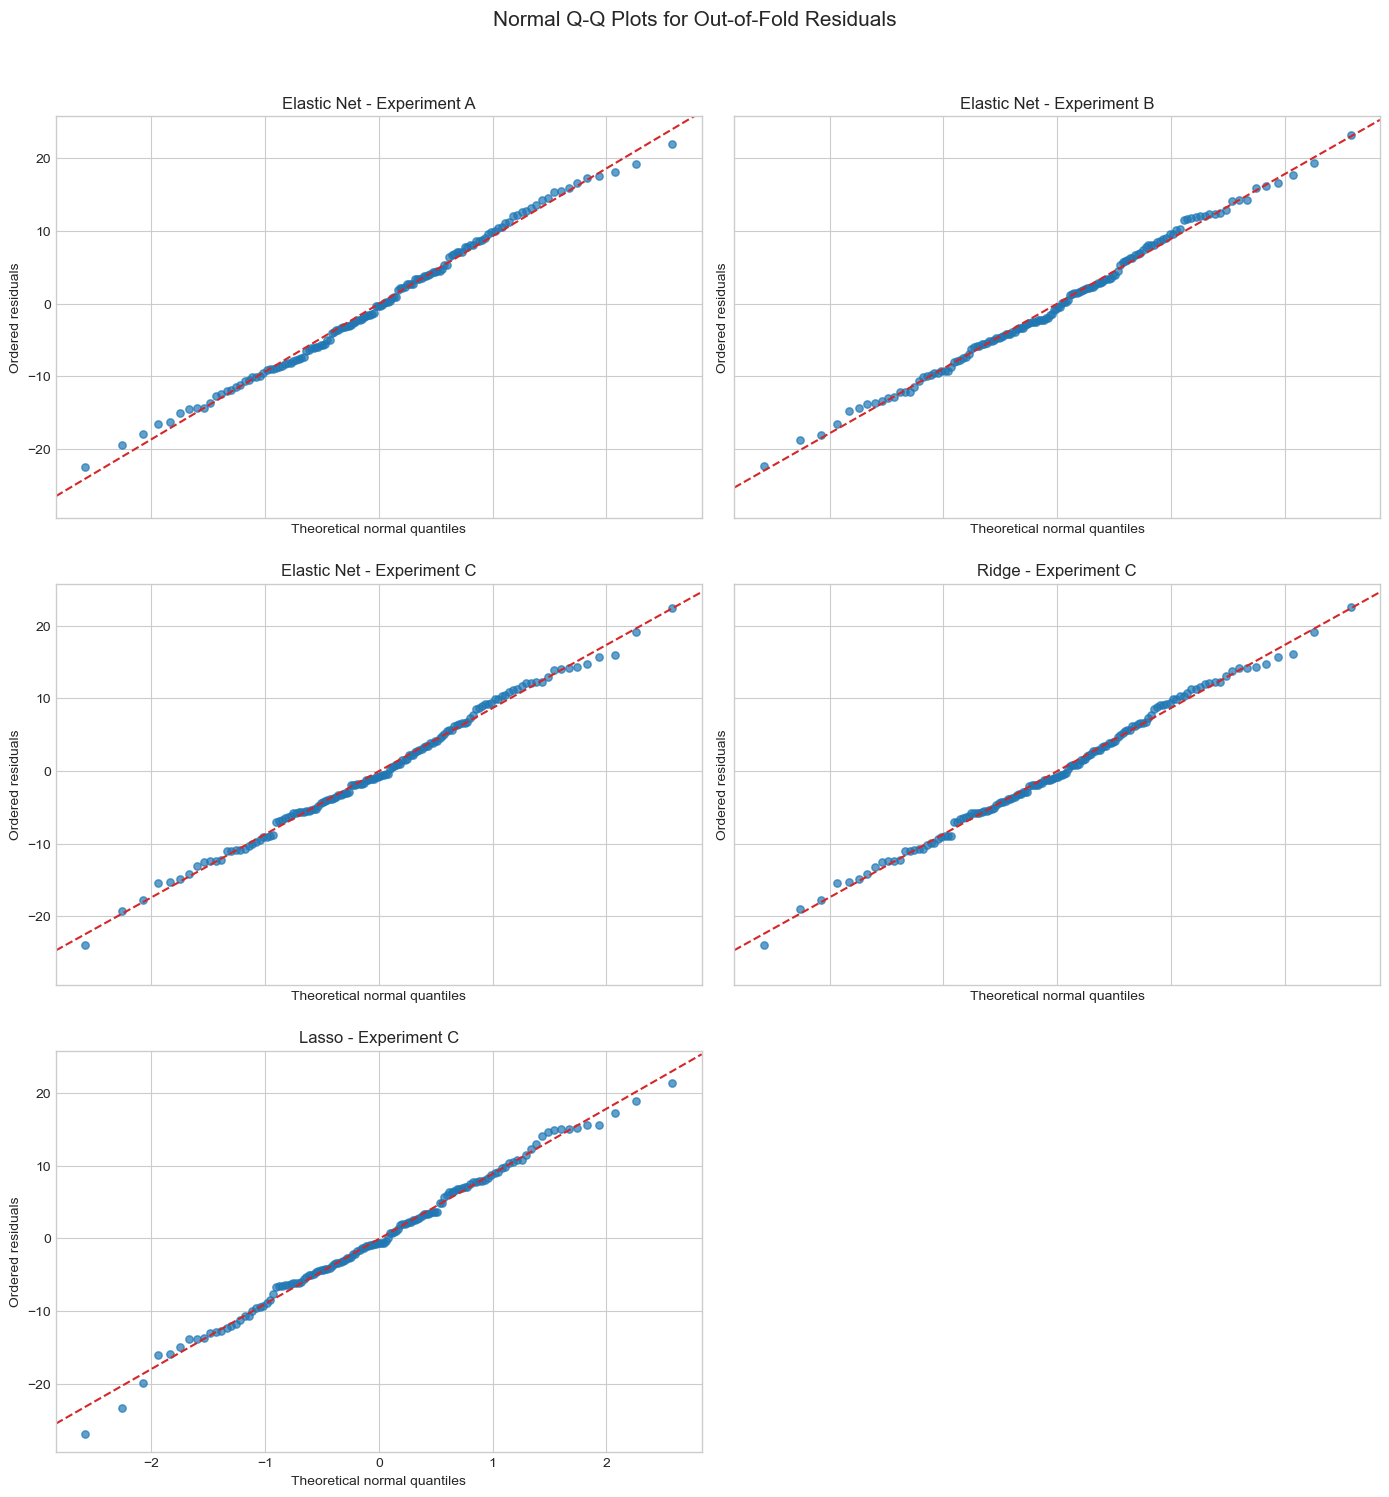

In [8]:
qq_values = []
for result in diagnostic_results:
    theoretical, ordered = stats.probplot(
        result["OOF_Results"]["Residual"], dist="norm", fit=False
    )
    qq_values.append((np.asarray(theoretical), np.asarray(ordered)))

x_limits = padded_limits(np.concatenate([values[0] for values in qq_values]))
y_limits = padded_limits(np.concatenate([values[1] for values in qq_values]))

fig, axes = diagnostic_axes(
    "Normal Q-Q Plots for Out-of-Fold Residuals"
)
for axis, result, (theoretical, ordered) in zip(
    axes, diagnostic_results, qq_values
):
    slope, intercept, _ = stats.probplot(
        result["OOF_Results"]["Residual"], dist="norm", fit=True
    )[1]
    reference_x = np.array(x_limits)
    axis.scatter(theoretical, ordered, alpha=0.7, s=28)
    axis.plot(
        reference_x,
        intercept + slope * reference_x,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
    )
    axis.set_title(result["Short_Label"])
    axis.set_xlim(x_limits)
    axis.set_ylim(y_limits)
    axis.set_xlabel("Theoretical normal quantiles")
    axis.set_ylabel("Ordered residuals")

fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.0)
plt.show()


## 9. Experiment C predictor correlation

This heatmap uses only development observations and all Experiment C predictors. Large positive or negative correlations reveal overlapping predictor information and help motivate coefficient shrinkage; correlation alone does not establish that a predictor is unnecessary.


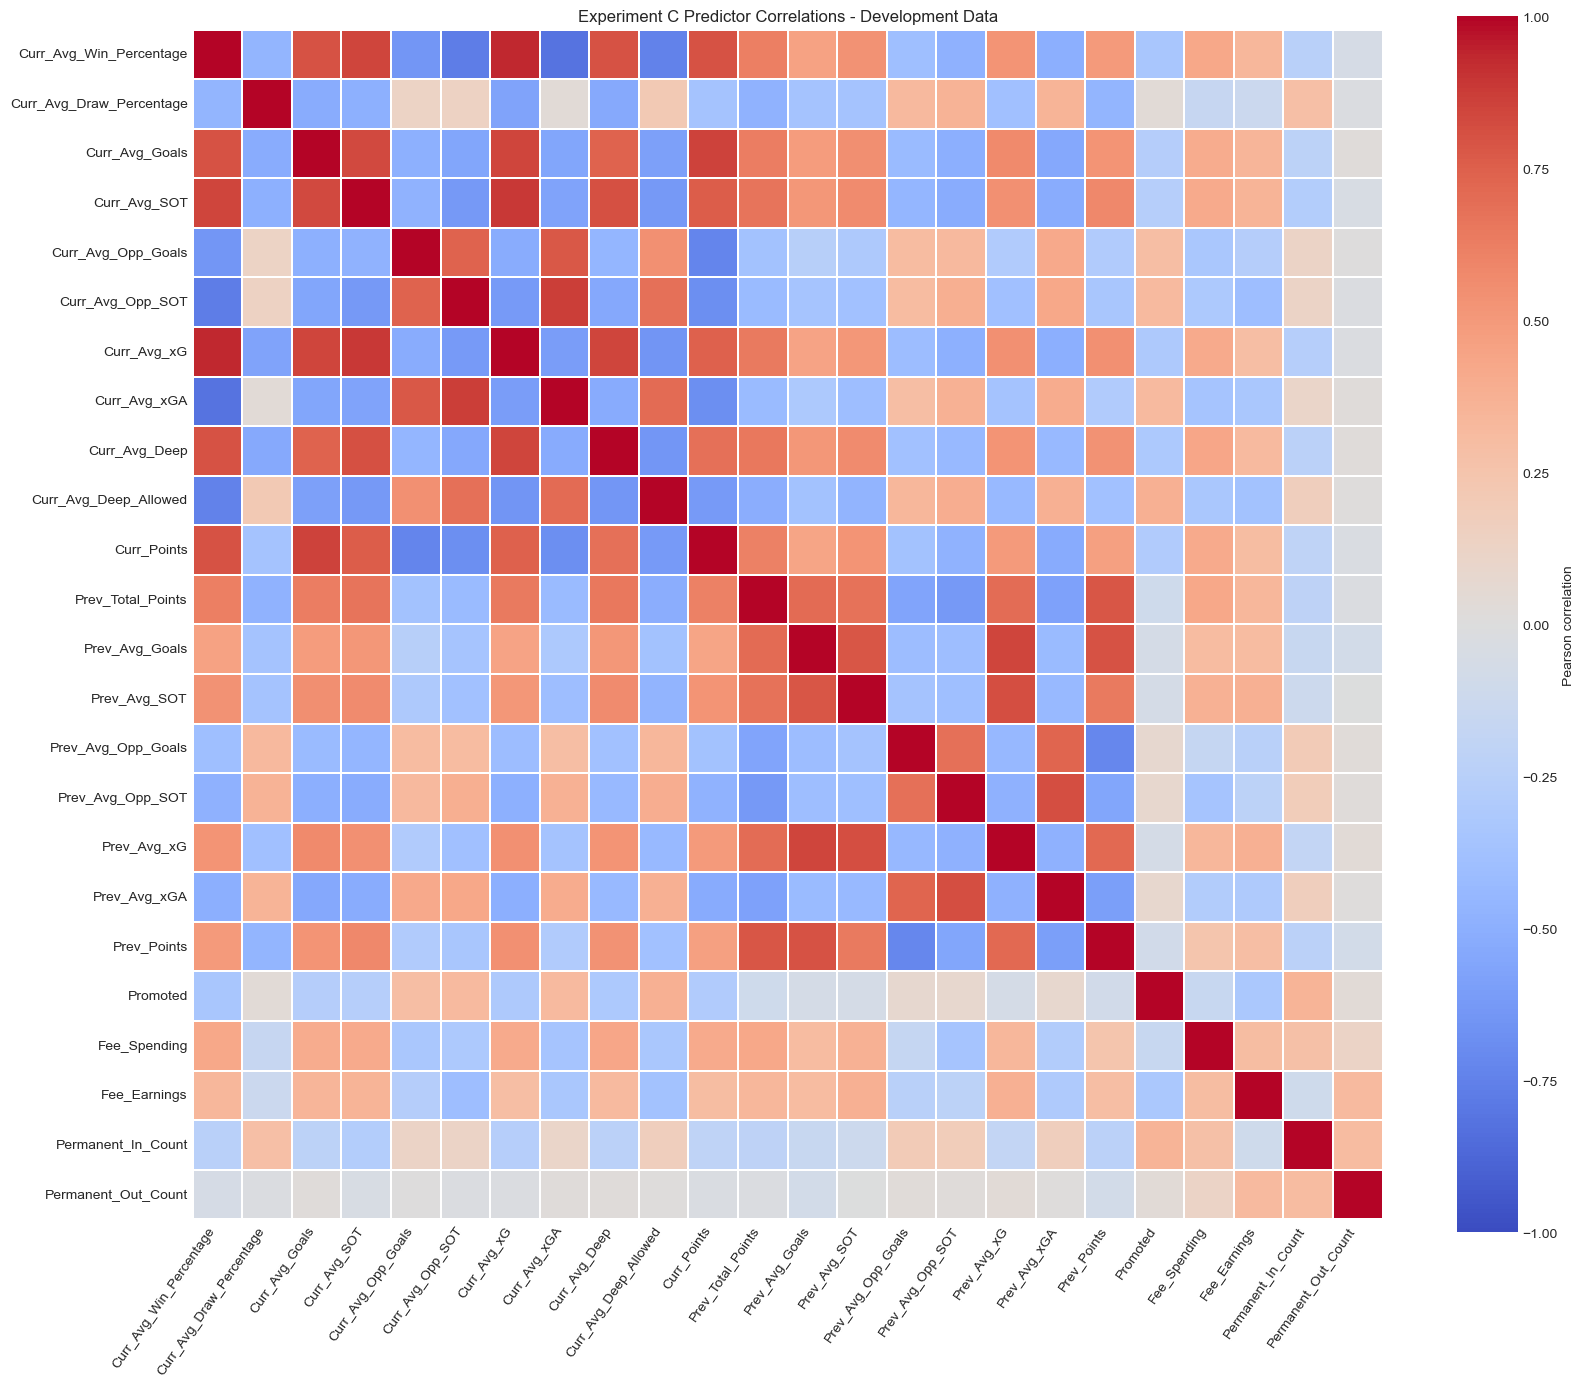

In [9]:
experiment_c_features = EXPERIMENTS[
    "Experiment C: Current + previous + transfers"
]
development_correlations = development[experiment_c_features].corr(
    method="pearson"
)

plt.figure(figsize=(17, 14))
sns.heatmap(
    development_correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.25,
    cbar_kws={"label": "Pearson correlation"},
)
plt.title("Experiment C Predictor Correlations - Development Data")
plt.xticks(rotation=55, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 10. Residual patterns across seasons

Season-specific residual distributions and means reveal whether models systematically overpredict or underpredict particular validation seasons. Differences may reflect temporal change, unusual league conditions, or sampling variation rather than a single definitive violation.


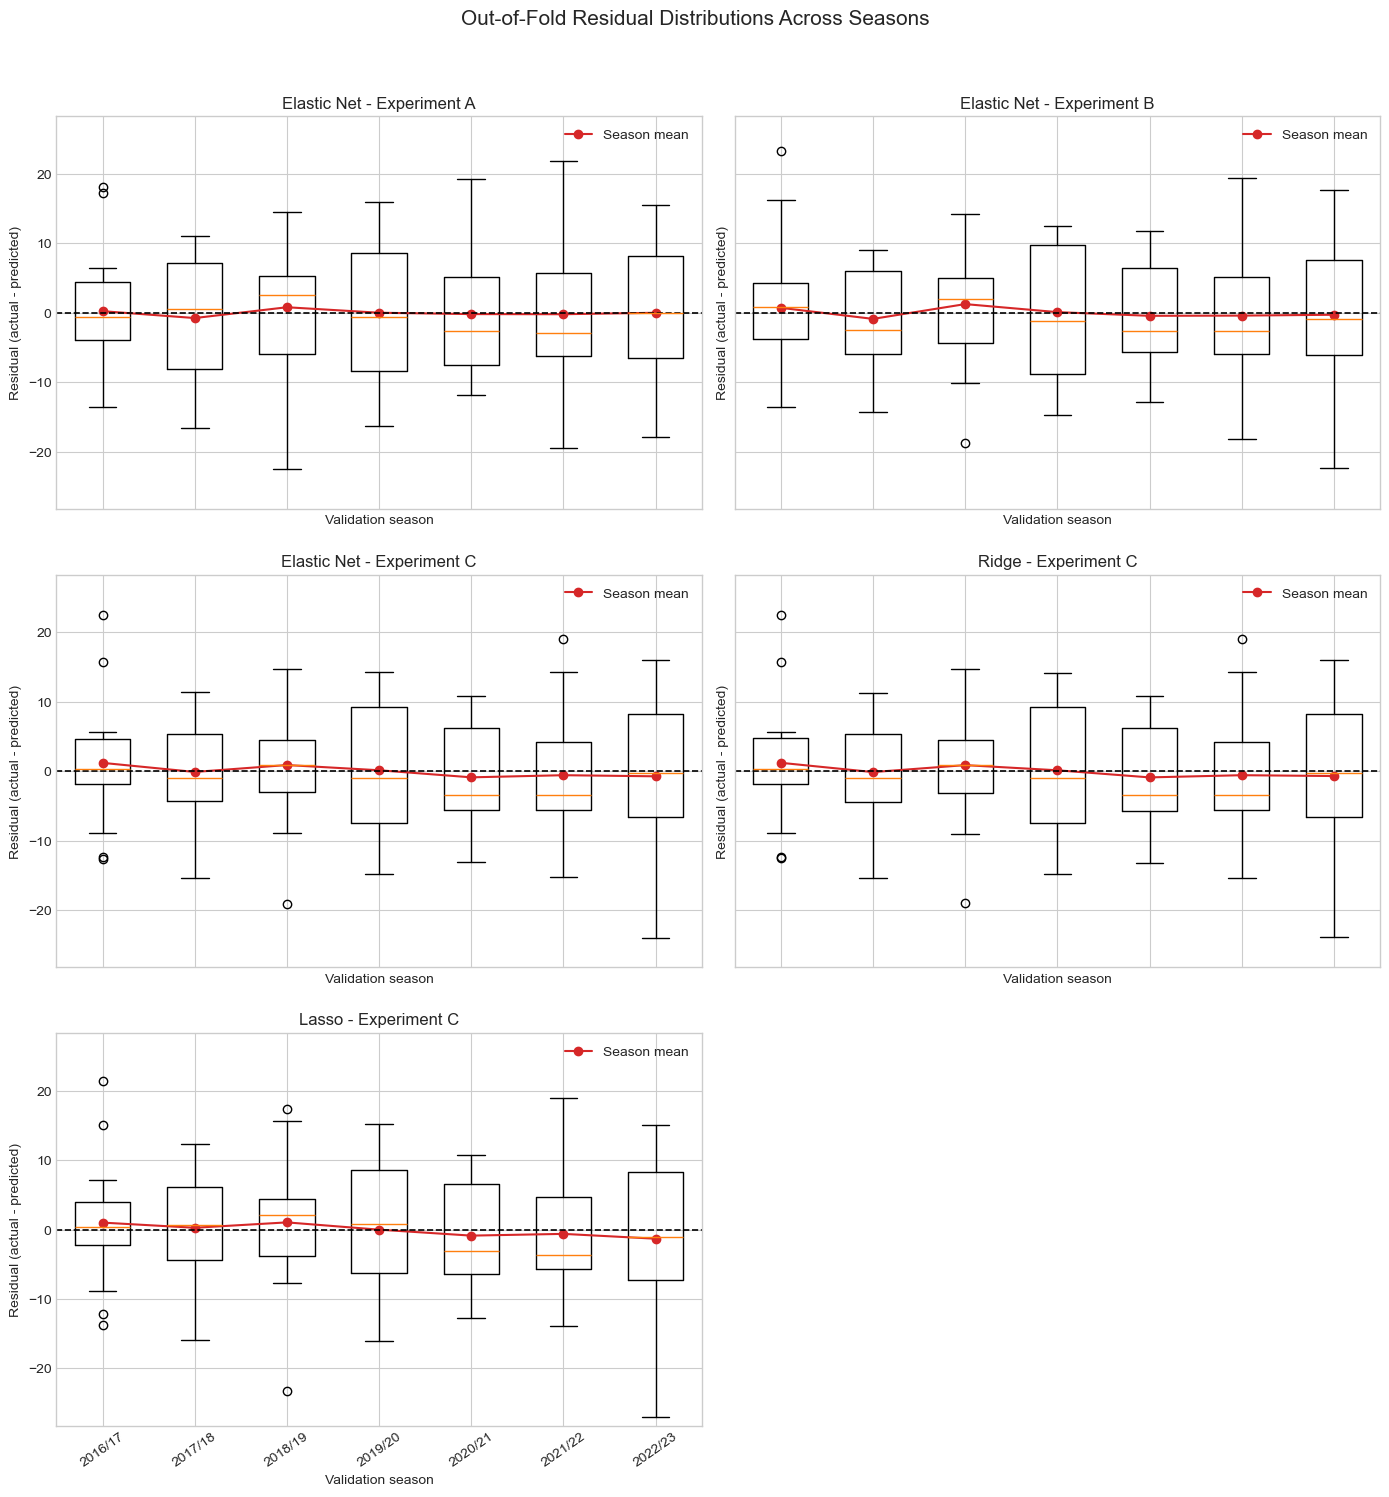

In [10]:
all_residuals = np.concatenate(
    [result["OOF_Results"]["Residual"] for result in diagnostic_results]
)
residual_limit = 1.05 * np.max(np.abs(all_residuals))
season_positions = np.arange(1, len(DEVELOPMENT_SEASONS) + 1)
season_labels = [SEASON_LABELS[season] for season in DEVELOPMENT_SEASONS]

fig, axes = diagnostic_axes(
    "Out-of-Fold Residual Distributions Across Seasons",
    sharex=True,
    sharey=True,
)
for axis, result in zip(axes, diagnostic_results):
    data = result["OOF_Results"]
    season_residuals = [
        data.loc[data["Season"].eq(season), "Residual"].to_numpy()
        for season in DEVELOPMENT_SEASONS
    ]
    season_means = [np.mean(values) for values in season_residuals]
    axis.boxplot(
        season_residuals,
        positions=season_positions,
        widths=0.6,
        showfliers=True,
    )
    axis.plot(
        season_positions,
        season_means,
        color="tab:red",
        marker="o",
        linewidth=1.5,
        label="Season mean",
    )
    axis.axhline(0, color="black", linestyle="--", linewidth=1.2)
    axis.set_title(result["Short_Label"])
    axis.set_ylim(-residual_limit, residual_limit)
    axis.set_xticks(season_positions, season_labels, rotation=35)
    axis.set_xlabel("Validation season")
    axis.set_ylabel("Residual (actual - predicted)")
    axis.legend(loc="best")

fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.0)
plt.show()


## 11. Within-club residual dependence

Each point links residuals for the same club in consecutive EPL seasons. Clubs without consecutive EPL appearances are not paired, and observations from unrelated clubs are never treated as adjacent. Visible alignment may suggest persistent club-specific forecast errors, but this diagnostic remains exploratory.


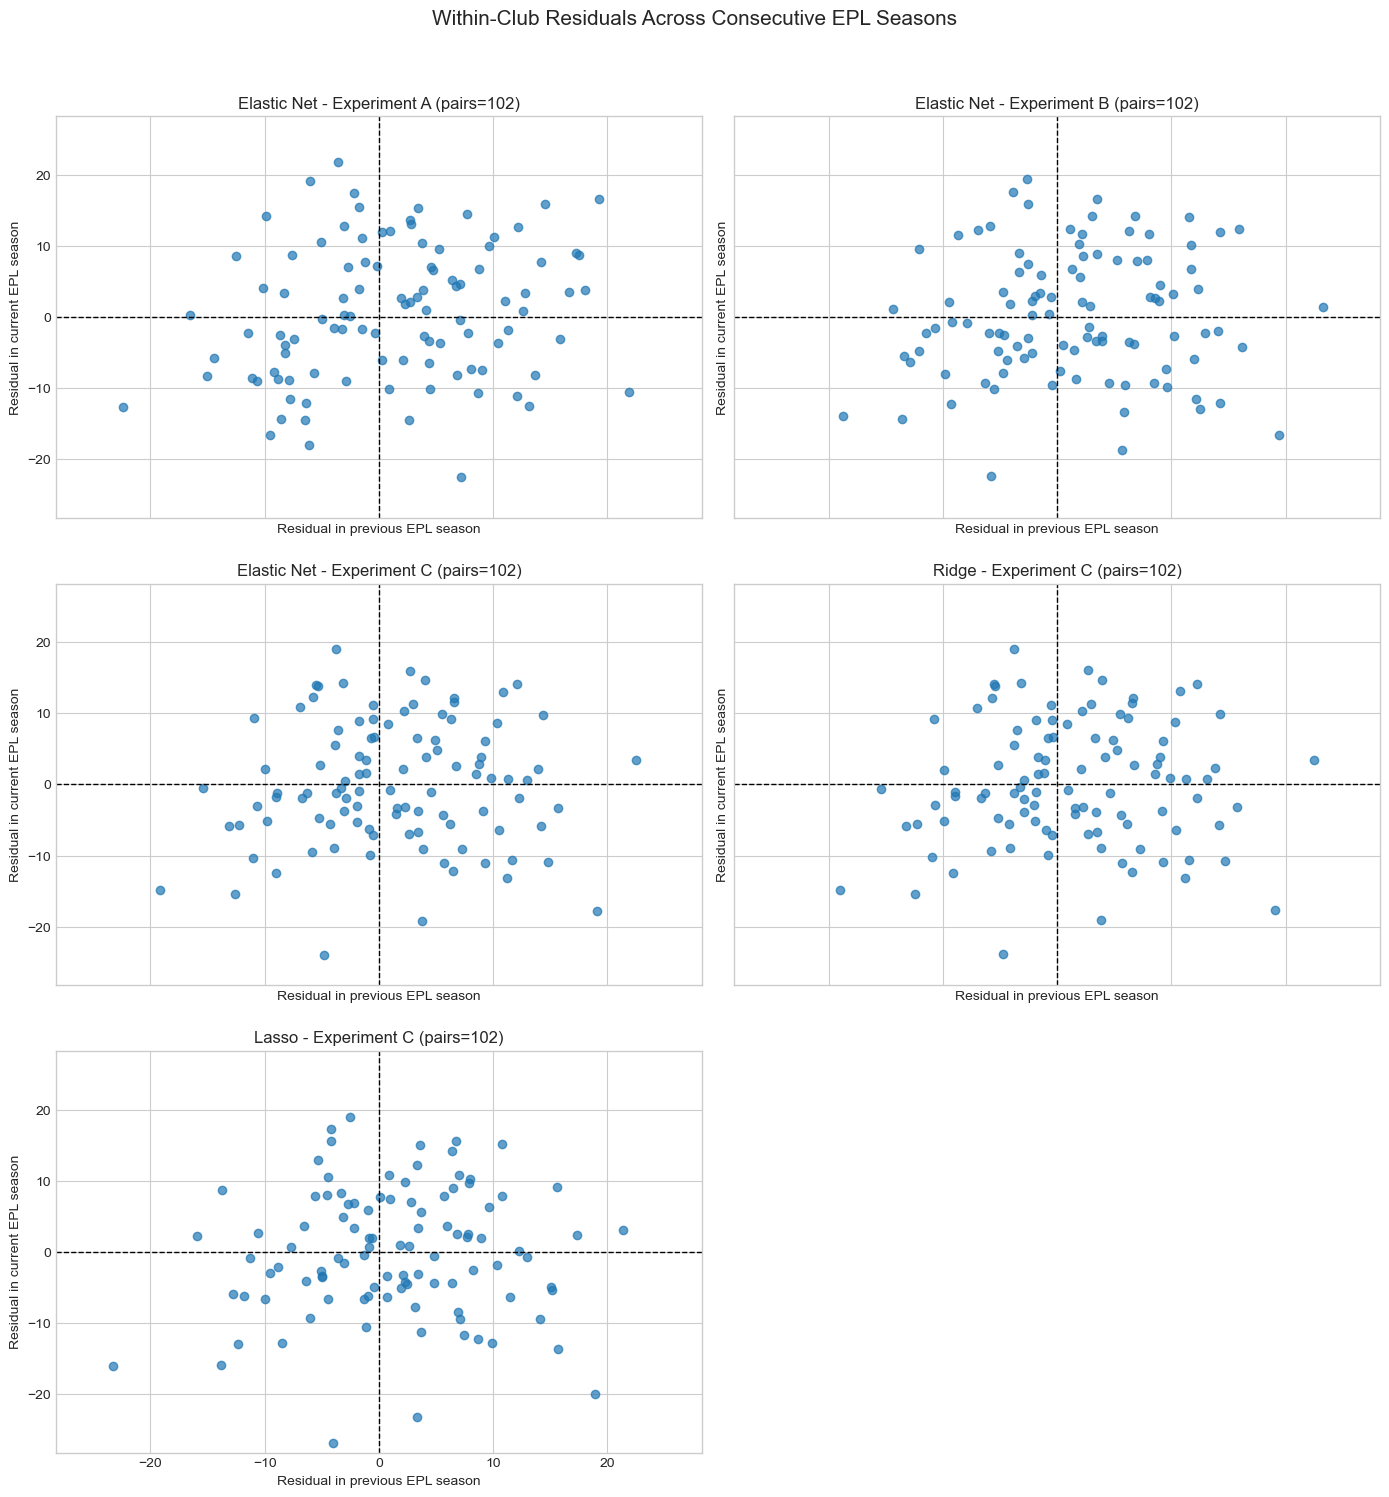

In [11]:
lagged_frames = []
for result in diagnostic_results:
    lagged = result["OOF_Results"].sort_values(["Team", "Season"]).copy()
    lagged["Previous_Season"] = lagged.groupby("Team")["Season"].shift(1)
    lagged["Lagged_Residual"] = lagged.groupby("Team")["Residual"].shift(1)
    lagged = lagged.loc[
        lagged["Season"].sub(lagged["Previous_Season"]).eq(1)
    ].copy()
    lagged_frames.append(lagged)

lag_limit = 1.05 * max(
    np.max(np.abs(frame[["Lagged_Residual", "Residual"]].to_numpy()))
    for frame in lagged_frames
)

fig, axes = diagnostic_axes(
    "Within-Club Residuals Across Consecutive EPL Seasons"
)
for axis, result, lagged in zip(axes, diagnostic_results, lagged_frames):
    axis.scatter(
        lagged["Lagged_Residual"],
        lagged["Residual"],
        alpha=0.7,
        s=36,
    )
    axis.axhline(0, color="black", linestyle="--", linewidth=1.0)
    axis.axvline(0, color="black", linestyle="--", linewidth=1.0)
    axis.set_title(f"{result['Short_Label']} (pairs={len(lagged)})")
    axis.set_xlim(-lag_limit, lag_limit)
    axis.set_ylim(-lag_limit, lag_limit)
    axis.set_xlabel("Residual in previous EPL season")
    axis.set_ylabel("Residual in current EPL season")

fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.0)
plt.show()
